In [1]:
import tensorflow.keras as tf
import matplotlib.pyplot as plt
import numpy as np

#### ImageDataGenerator:
1. Load data
2. Resized the Image - target_size
3. Transform(zoom, rotate)
4. Scaling(0-255 to 0-1)

In [2]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

In [3]:
datagen = ImageDataGenerator(rescale=1./255)

In [4]:
train_generator = datagen.flow_from_directory('C:/Users/DELL/Desktop/FBS/Data Science/Datasets/dataset/dataset/training_set', target_size=(64,64),class_mode='binary')

Found 7115 images belonging to 2 classes.


In [5]:
test_generator = datagen.flow_from_directory('C:/Users/DELL/Desktop/FBS/Data Science/Datasets/dataset/dataset/test_set', target_size=(64,64),class_mode='binary')

Found 496 images belonging to 2 classes.


In [6]:
train_generator

In [7]:
data, label = next(train_generator)

In [8]:
data.shape

(32, 64, 64, 3)

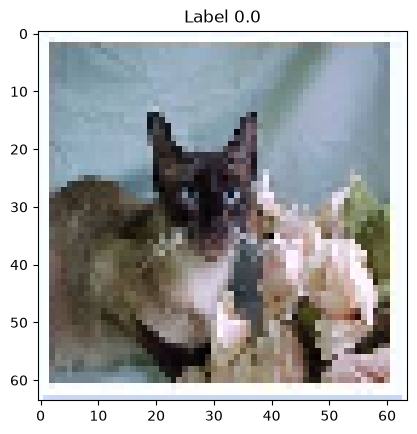

In [9]:
i = 20
plt.imshow(data[i])
plt.title(f'Label {label[i]}')
plt.show()

In [12]:
cnn = tf.models.Sequential()
cnn.add(tf.layers.Conv2D(filters=32, kernel_size=3, activation='relu', input_shape=[64,64,3]))
cnn.add(tf.layers.MaxPool2D(pool_size=2, strides=2))
cnn.add(tf.layers.Conv2D(filters=32, kernel_size=3, activation='relu'))
cnn.add(tf.layers.MaxPool2D(pool_size=2, strides=2))
cnn.add(tf.layers.Flatten())
cnn.add(tf.layers.Dense(units=128, activation='relu'))
cnn.add(tf.layers.Dense(units=1, activation='sigmoid'))
cnn.compile(loss='binary_crossentropy',metrics=['accuracy'], optimizer='adam')

C:\Users\DELL\AppData\Local\Programs\Python\Python313\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [13]:
cnn.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                      │ (None, 62, 62, 32)          │             896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d (MaxPooling2D)         │ (None, 31, 31, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_1 (Conv2D)                    │ (None, 29, 29, 32)          │           9,248 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_1 (MaxPooling2D)       │ (None, 14, 14, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten (Flatten)                    │ (None, 6272)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 128)                 │         802,944 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 1)                   │             129 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 813,217 (3.10 MB)

 Trainable params: 813,217 (3.10 MB)

 Non-trainable params: 0 (0.00 B)

In [14]:
cnn.fit(x=train_generator, epochs=3)

Epoch 1/3
223/223 ━━━━━━━━━━━━━━━━━━━━ 79s 344ms/step - accuracy: 0.5691 - loss: 0.6764
Epoch 2/3
223/223 ━━━━━━━━━━━━━━━━━━━━ 19s 86ms/step - accuracy: 0.6537 - loss: 0.6154
Epoch 3/3
223/223 ━━━━━━━━━━━━━━━━━━━━ 17s 77ms/step - accuracy: 0.7257 - loss: 0.5421


In [15]:
cnn.evaluate(test_generator)

16/16 ━━━━━━━━━━━━━━━━━━━━ 4s 233ms/step - accuracy: 0.8065 - loss: 0.4439


[0.443912148475647, 0.8064516186714172]

In [16]:
pred = cnn.predict(test_generator)
predicted_class = []
for x in pred:
    if(x >= 0.5):
        predicted_class.append(1)
    else:
        predicted_class.append(0)

16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 52ms/step


In [17]:
from keras.preprocessing import image

In [18]:
from keras.utils import load_img
from keras.utils import img_to_array

In [44]:
new_image = load_img("C:/Users/DELL/Desktop/FBS/Data Science/Datasets/dataset/dataset/single_prediction/cat_or_dog_1.jpg", target_size=(64,64))

In [45]:
new_image = img_to_array(new_image)

In [46]:
new_image.shape

(64, 64, 3)

In [47]:
new_image = np.expand_dims(new_image, axis=0)

In [48]:
result = cnn.predict(new_image)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 60ms/step


In [49]:
result[0][0]

np.float32(1.0)

In [50]:
if(result[0][0] >= 0.5):
    print('Dog')
else:
    print('Cat')

Dog
